# 04b · TimesFM-3 Forecasts (Google foundation model)

**Owner:** Max · **Reads:** notebook 01 outputs · **Feeds:** Elena (calibration, ensemble), Prateek (hybrid residual model)

TimesFM-3 is Google's pretrained time series model (released Aug 2026, ~330M parameters). Like Chronos-2, it forecasts each product's next 28 days **with no training on our data**.
It's a decoder-only transformer that reads the sales history in 32-day patches and outputs 9 percentiles (10th–90th).

**Two runs** (same design as 04a, so the two models compare like with like)
| Run | Model name in files | What the model sees |
|---|---|---|
| Zero-shot | `timesfm3_zs` | Sales history only |
| With covariates | `timesfm3_cov` | Sales history + price, discount ratio, SNAP days, events, Christmas |

**Seven windows per run:** `bt_4` … `bt_1`, `val_1`, `val_2`, `test` (same as 04a).

**Output:** `data/forecasts/<model>_<window>.parquet` with columns
`unique_id, ds, model, window, forecast` (the median) + `q0.1 … q0.9`. (TimesFM-3 doesn't output a mean.)

**Runtime:** **Runtime → Change runtime type → T4 GPU**. Start with `SAMPLE = True`, then `SAMPLE = False`.
If Colab disconnects, run everything again: finished windows are skipped.

**License note:** the `timesfm` package code is Apache 2.0; the model weights use Google's TimesFM non-commercial license. Fine for coursework.

## 0 · Settings

In [1]:
SAMPLE      = True      # True = 100-product smoke test; False = all ~12,200 California series
RUNS        = ["zs", "cov"]   # zero-shot, with covariates
N_BACKTEST  = 4         # extra 28-day windows before val_1 (training data for the hybrid model)
BATCH_SIZE  = 32        # series per GPU batch; lowered automatically if the GPU runs out of memory
OVERWRITE   = False     # True = redo windows that already have a forecast file

DRIVE_DIR   = "/content/drive/MyDrive/AML_Term_Project"
DATA_DIR    = f"{DRIVE_DIR}/data"
OUT_DIR     = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"

MODEL_ID    = "google/timesfm-3.0-pytorch"
COVARIATES  = ["sell_price", "price_ratio", "snap", "is_event", "is_christmas"]   # known in advance for future dates

## 1 · Install and connect

In [2]:
!pip install -q "timesfm[torch]==3.0.2"

In [3]:
import os, json, time, dataclasses
import numpy as np
import pandas as pd
import torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: using the paths in Settings as-is.")

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Set Runtime -> Change runtime type -> T4 GPU, or expect this to be slow.")

Mounted at /content/drive
Device: cuda | torch 2.11.0+cu130


## 2 · Load data and windows

In [4]:
df = pd.read_parquet(f"{DATA_DIR}/{'ca_sample100' if SAMPLE else 'ca_sales'}.parquet")
df["unique_id"] = df["unique_id"].astype(str)
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

with open(f"{DATA_DIR}/windows.json") as f:
    wjson = json.load(f)
H = wjson["horizon"]

# Shared window list (identical to 04a): 4 backtests right before val_1, then val_1, val_2, test.
val1_start = pd.Timestamp(wjson["val_1"]["start"])
windows = {}
for k in range(N_BACKTEST, 0, -1):
    start = val1_start - pd.Timedelta(days=H * k)
    windows[f"bt_{k}"] = (start, start + pd.Timedelta(days=H - 1))
for name in ["val_1", "val_2", "test"]:
    windows[name] = (pd.Timestamp(wjson[name]["start"]), pd.Timestamp(wjson[name]["end"]))

print(f"{df['unique_id'].nunique():,} series, {len(df):,} rows")
pd.DataFrame({w: {"start": s.date(), "end": e.date()} for w, (s, e) in windows.items()}).T

100 series, 146,311 rows


,start,end
bt_4,2015-11-09,2015-12-06
bt_3,2015-12-07,2016-01-03
bt_2,2016-01-04,2016-01-31
bt_1,2016-02-01,2016-02-28
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


## 3 · Load TimesFM-3

In [5]:
from timesfm3 import TimesFM3Forecaster
model = TimesFM3Forecaster.from_pretrained(MODEL_ID, device=DEVICE, per_core_batch_size=BATCH_SIZE)
QUANTILES = list(model.config.quantiles)
print("Loaded", MODEL_ID, "| quantiles:", QUANTILES)

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.32GB            

model.safetensors: downloading bytes:           |  0.00B            

Loaded google/timesfm-3.0-pytorch | quantiles: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


## 4 · Forecast one window
TimesFM-3 takes one array per product rather than a table:
- **Context** = the product's sales before the window starts (the model never sees the window's actual sales)
- **Covariates** (cov run) = one array per covariate covering the history **and** the 28 window days.
  The model reads the extra 28 values as "known future" inputs.
- Products launched on or after the window start have no history, so they're skipped for that window

In [6]:
def build_inputs(run, start, end):
    hist = df[df["ds"] < start]
    ids = hist["unique_id"].unique()
    fut = df[(df["ds"] >= start) & (df["ds"] <= end) & df["unique_id"].isin(ids)]
    if run == "cov":
        n_fut = fut.groupby("unique_id").size()
        ids = n_fut[n_fut == H].index.values          # need all 28 future rows for covariates
    hist_g = dict(tuple(hist[hist["unique_id"].isin(ids)].groupby("unique_id", sort=True)))
    fut_g = dict(tuple(fut[fut["unique_id"].isin(ids)].groupby("unique_id", sort=True))) if run == "cov" else {}

    ids = sorted(hist_g)
    contexts, covs = [], []
    for uid in ids:
        h = hist_g[uid]
        contexts.append(h["y"].to_numpy(np.float32))
        if run == "cov":
            both = pd.concat([h[COVARIATES], fut_g[uid][COVARIATES]])
            covs.append(both.to_numpy(np.float32).T)    # shape (n_covariates, context + 28)
    return ids, contexts, (covs if run == "cov" else None)


def forecast_window(run, wname, start, end, batch_size=BATCH_SIZE):
    ids, contexts, covs = build_inputs(run, start, end)
    while True:
        try:
            model.config = dataclasses.replace(model.config, per_core_batch_size=batch_size)
            outs = list(model.predict_batch(
                contexts=contexts, horizon=H, past_future_covariates=covs,
                ts_ids=ids, return_quantiles=True, make_positive=True,
            ))
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            batch_size //= 2
            print(f"  GPU out of memory -> retrying with batch_size={batch_size}")
            if batch_size < 1:
                raise

    dates = pd.date_range(start, periods=H, freq="D")
    q = np.stack([o.quantiles for o in outs])          # (series, 28, n_quantiles)
    res = pd.DataFrame({
        "unique_id": np.repeat([o.ts_id for o in outs], H),
        "ds": np.tile(dates, len(outs)),
        "model": f"timesfm3_{run}",
        "window": wname,
        "forecast": np.concatenate([o.forecast for o in outs]).clip(min=0).astype("float32"),   # median
    })
    for j, ql in enumerate(QUANTILES):
        res[f"q{ql}"] = q[:, :, j].ravel().clip(min=0).astype("float32")
    return res, batch_size

## 5 · Run everything (skips windows already saved)

In [7]:
log_rows = []
for run in RUNS:
    for wname, (start, end) in windows.items():
        path = f"{OUT_DIR}/timesfm3_{run}_{wname}.parquet"
        if os.path.exists(path) and not OVERWRITE:
            print(f"skip  timesfm3_{run:3s} {wname:6s} (already saved)")
            continue
        t0 = time.time()
        res, used_bs = forecast_window(run, wname, start, end)
        res.to_parquet(path, index=False)
        secs = time.time() - t0
        n = res["unique_id"].nunique()
        print(f"done  timesfm3_{run:3s} {wname:6s} {n:6,} series  {secs:6.1f}s")
        log_rows.append({"model": f"timesfm3_{run}", "window": wname, "series": n, "seconds": round(secs, 1),
                         "batch_size": used_bs, "device": DEVICE, "sample": SAMPLE,
                         "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")})

if log_rows:
    log_path = f"{OUT_DIR}/run_log.csv"
    new = pd.DataFrame(log_rows)
    new.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    display(new)

done  timesfm3_zs  bt_4      100 series     3.4s
done  timesfm3_zs  bt_3      100 series     2.4s
done  timesfm3_zs  bt_2      100 series     2.1s
done  timesfm3_zs  bt_1      100 series     2.2s
done  timesfm3_zs  val_1     100 series     2.3s
done  timesfm3_zs  val_2     100 series     2.2s
done  timesfm3_zs  test      100 series     2.5s
done  timesfm3_cov bt_4      100 series     8.5s
done  timesfm3_cov bt_3      100 series     7.8s
done  timesfm3_cov bt_2      100 series     9.1s
done  timesfm3_cov bt_1      100 series     9.5s
done  timesfm3_cov val_1     100 series     8.5s
done  timesfm3_cov val_2     100 series     8.7s
done  timesfm3_cov test      100 series    10.4s


,model,window,series,seconds,batch_size,device,sample,run_at
0,timesfm3_zs,bt_4,100,3.4,32,cuda,True,2026-11-03 23:01
1,timesfm3_zs,bt_3,100,2.4,32,cuda,True,2026-11-03 23:01
2,timesfm3_zs,bt_2,100,2.1,32,cuda,True,2026-11-03 23:01
3,timesfm3_zs,bt_1,100,2.2,32,cuda,True,2026-11-03 23:01
4,timesfm3_zs,val_1,100,2.3,32,cuda,True,2026-11-03 23:01
5,timesfm3_zs,val_2,100,2.2,32,cuda,True,2026-11-03 23:01
6,timesfm3_zs,test,100,2.5,32,cuda,True,2026-11-03 23:01
7,timesfm3_cov,bt_4,100,8.5,32,cuda,True,2026-11-03 23:01
8,timesfm3_cov,bt_3,100,7.8,32,cuda,True,2026-11-03 23:01
9,timesfm3_cov,bt_2,100,9.1,32,cuda,True,2026-11-03 23:01


## 6 · Quick check against the baseline and Chronos-2
Not the official evaluation (that's notebook 05). This confirms the forecasts are sensible and gives a first look
at how TimesFM-3 compares with Chronos-2 (if 04a has already been run on the same data).

In [8]:
actual = df[["unique_id", "ds", "y"]]
lag7 = actual.copy()
lag7["ds"] = lag7["ds"] + pd.Timedelta(days=7)
lag7 = lag7.rename(columns={"y": "naive"})

rows = []
for run in RUNS:
    for wname in windows:
        f = pd.read_parquet(f"{OUT_DIR}/timesfm3_{run}_{wname}.parquet")
        m = f.merge(actual, on=["unique_id", "ds"]).merge(lag7, on=["unique_id", "ds"], how="left")
        m["naive"] = m["naive"].fillna(0)
        row = {"run": run, "window": wname,
               "MAE timesfm3": (m["forecast"] - m["y"]).abs().mean(),
               "MAE naive": (m["naive"] - m["y"]).abs().mean()}
        cpath = f"{OUT_DIR}/chronos2_{run}_{wname}.parquet"
        if os.path.exists(cpath):     # same products, same days -> fair side-by-side
            c = pd.read_parquet(cpath)[["unique_id", "ds", "forecast"]].rename(columns={"forecast": "chronos"})
            mc = m.merge(c, on=["unique_id", "ds"])
            row["MAE chronos2"] = (mc["chronos"] - mc["y"]).abs().mean()
        rows.append(row)
check = pd.DataFrame(rows)
check["improvement vs naive"] = (1 - check["MAE timesfm3"] / check["MAE naive"]).map("{:.0%}".format)
check.round(3)

,run,window,MAE timesfm3,MAE naive,MAE chronos2,improvement vs naive
0,zs,bt_4,0.895,1.211,0.896,26%
1,zs,bt_3,0.876,1.163,0.860,25%
2,zs,bt_2,0.947,1.340,0.969,29%
3,zs,bt_1,0.942,1.269,0.933,26%
4,zs,val_1,0.964,1.226,0.958,21%
5,zs,val_2,0.912,1.259,0.922,28%
6,zs,test,0.981,1.297,1.012,24%
7,cov,bt_4,0.897,1.211,0.884,26%
8,cov,bt_3,0.873,1.163,0.861,25%
9,cov,bt_2,0.942,1.340,0.952,30%


## 7 · Look at a few products
Actual sales (black) vs. TimesFM-3's median and 10th–90th percentile range on the **test** window.

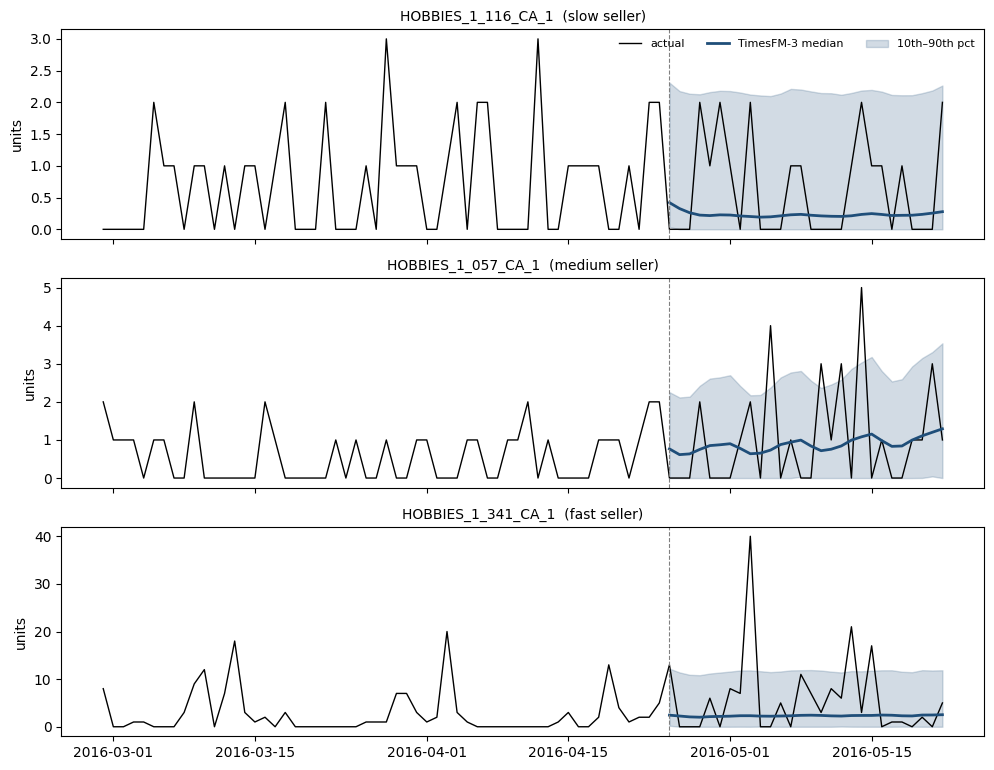

In [9]:
import matplotlib.pyplot as plt
run = "cov" if "cov" in RUNS else RUNS[0]
f = pd.read_parquet(f"{OUT_DIR}/timesfm3_{run}_test.parquet")
start, end = windows["test"]
static = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
static["unique_id"] = static["unique_id"].astype(str)
pick = (static[static["unique_id"].isin(f["unique_id"])]
        .groupby("sales_speed", observed=True)["unique_id"].first())

fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.6 * len(pick)), sharex=True)
for ax, (speed, uid) in zip(np.atleast_1d(axes), pick.items()):
    hist = df[(df["unique_id"] == uid) & (df["ds"] >= start - pd.Timedelta(days=56)) & (df["ds"] <= end)]
    fc = f[f["unique_id"] == uid]
    ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="actual")
    ax.plot(fc["ds"], fc["forecast"], color="#1f4e79", lw=2, label="TimesFM-3 median")
    ax.fill_between(fc["ds"], fc["q0.1"], fc["q0.9"], color="#1f4e79", alpha=0.2, label="10th–90th pct")
    ax.axvline(start, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{uid}  ({speed} seller)", fontsize=10); ax.set_ylabel("units")
np.atleast_1d(axes)[0].legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()
if not SAMPLE:
    os.makedirs(f"{DATA_DIR}/figures", exist_ok=True)
    plt.savefig(f"{DATA_DIR}/figures/11_timesfm3_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## What to report back
Download this notebook (**File → Download → .ipynb**) with outputs into *Project Code*; Claude commits it to GitHub.
Look at:
1. Section 5: seconds per window
2. Section 6: does TimesFM-3 beat the naive baseline? How does it compare with Chronos-2? Does `cov` help?
3. Section 7: compare these plots with 04a's. Does TimesFM-3 also forecast low for spiky products?